# Laboratorio · Sesión 3 — Calidad de datos: perfilado, reglas y métricas
**PY-EAN · Python para Procesamiento, Calidad y Automatización de Datos** · Universidad Ean

**Caso:** la gerencia pregunta *"¿podemos confiar en la base de afiliados?"*. No basta con "se ve bien":
vas a responder con un **reporte de calidad** — % de cumplimiento por regla, por dimensión y un índice global —
y a separar los registros válidos de los que van a **cuarentena**.

**Cómo trabajar:** Shift + Enter de arriba hacia abajo · completa donde dice `# ✏️ TU CÓDIGO AQUÍ` ·
guarda tu copia en Drive (**Archivo → Guardar una copia en Drive**).

> Todos los datos son sintéticos. No corresponden a personas reales.

## Parte 0 · Preparar el entorno (5 min)

In [1]:
# ▶️ Ejecuta esta celda primero (Shift + Enter)
import os
import pandas as pd

URL_DATOS = "https://raw.githubusercontent.com/Hackwy402/python-procesamiento-ean/main/datos/"
# Si subiste la carpeta "datos" a Colab (o trabajas en tu PC) se usa la copia local;
# si no, se leen los datos directamente desde GitHub.
for carpeta in ["datos/", "../datos/", "/content/datos/"]:
    if os.path.exists(carpeta + "afiliados.csv"):
        RUTA = carpeta
        break
else:
    RUTA = URL_DATOS

pd.set_option("display.max_columns", 30)
print("Leyendo datos desde:", RUTA)

Leyendo datos desde: ../datos/


In [2]:
import re
import unicodedata
import numpy as np
import matplotlib.pyplot as plt

HOY = pd.Timestamp("2026-10-31")     # fecha de corte del caso
SMMLV = 1_750_905                    # salario mínimo 2026 (dato de referencia del curso)

# dtype=str: documentos y teléfonos son TEXTO (no queremos que pandas los vuelva números)
afiliados = pd.read_csv(RUTA + "afiliados.csv", dtype={"numero_documento": str, "telefono": str})
cat_ciudades = pd.read_excel(RUTA + "oficinas.xlsx", sheet_name="ciudades", dtype={"codigo_dane": str})
pqrs = pd.read_csv(RUTA + "pqrs.csv")
aportes = pd.read_csv(RUTA + "aportes/aportes_2026-03.csv")

print("afiliados:", afiliados.shape, "| pqrs:", pqrs.shape, "| aportes marzo:", aportes.shape)

afiliados: (3120, 14) | pqrs: (1500, 8) | aportes marzo: (1770, 6)


## Parte 1 · Perfilado (15 min)
Antes de escribir reglas, mira qué hay.

**✏️ Ejercicio 1.** Calcula el **porcentaje** de vacíos por columna de `afiliados`, redondeado a 2 decimales y ordenado
de mayor a menor. Pista: `isna().mean() * 100`.

In [3]:
(afiliados.isna().mean() * 100).round(2).sort_values(ascending=False)

genero              2.05
salario_base        1.03
telefono            0.71
numero_documento    0.48
email               0.48
id_afiliado         0.00
tipo_documento      0.00
nombres             0.00
apellidos           0.00
fecha_nacimiento    0.00
ciudad              0.00
departamento        0.00
fecha_afiliacion    0.00
estado              0.00
dtype: float64

**✏️ Ejercicio 2.** ¿Cuántos valores distintos tiene cada columna (`nunique`)? Compara `id_afiliado` y
`numero_documento` contra el número de filas. ¿Qué te dice eso?

In [4]:
print("Filas:", len(afiliados))
afiliados.nunique()

Filas: 3120


id_afiliado         3030
tipo_documento         2
numero_documento    2985
nombres              844
apellidos           1012
fecha_nacimiento    2789
genero                10
ciudad                39
departamento          15
fecha_afiliacion    2585
salario_base        1981
email               2974
telefono            2961
estado                 8
dtype: int64

**✏️ Ejercicio 3.** Completa la función `perfilar(df)` para que devuelva **una fila por columna** con:
`tipo`, `pct_nulos`, `distintos` y `ejemplo` (el primer valor no vacío).

In [6]:
def perfilar(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "pct_nulos": (df.isna().mean() * 100).round(2),
        "distintos": df.nunique(),
        "ejemplo": df.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
    })

perfilar(afiliados)

,tipo,pct_nulos,distintos,ejemplo
id_afiliado,str,0.00,3030,AF100026
tipo_documento,str,0.00,2,CC
numero_documento,str,0.48,2985,940974240
nombres,str,0.00,844,PATRICIA
apellidos,str,0.00,1012,Ortiz Ortiz
fecha_nacimiento,str,0.00,2789,1971-09-13
genero,str,2.05,10,F
ciudad,str,0.00,39,Medellín
departamento,str,0.00,15,Antioquia
fecha_afiliacion,str,0.00,2585,2007-03-17


**✏️ Ejercicio 4.** Reutiliza tu función: perfila `pqrs` y `aportes`. ¿Qué columnas tienen vacíos? ¿Tiene sentido que los tengan?

In [7]:
display(perfilar(pqrs))
display(perfilar(aportes))

,tipo,pct_nulos,distintos,ejemplo
radicado,str,0.00,1500,PQRS-2026-000001
id_afiliado,str,0.00,1200,AF101316
tipo,str,0.00,5,Petición
tema,str,0.00,6,Devolución de aportes
canal,str,0.00,4,Correo electrónico
fecha_radicacion,str,0.00,299,2026-09-01
fecha_respuesta,str,12.27,295,2026-09-10
estado,str,0.00,3,Cerrado


,tipo,pct_nulos,distintos,ejemplo
id_afiliado,str,0.0,1765,AF100026
periodo,str,0.0,1,2026-03
ibc,int64,0.0,1204,1819000
valor_aporte,int64,0.0,1215,291040
fecha_pago,str,0.0,66,2026-04-17
operador,str,0.0,5,Aportes en Línea


✍️ *Tu respuesta:* En `pqrs` el único campo con vacíos es `fecha_respuesta` (12,27 %): son las PQRS
que todavía están **abiertas o en trámite**, así que el vacío es informativo (aún no hay respuesta) y no un error
de captura. Por eso la regla correcta no es exigir la fecha siempre, sino exigirla **cuando el estado es `Cerrado`**
(la regla `cerrado_con_fecha`). En `aportes` no hay vacíos: el archivo del periodo ya viene completo; si faltara
`fecha_pago`, habría que distinguir entre "no pagado" y "dato perdido" antes de tratarlo como error.

## Parte 2 · Reglas como máscaras booleanas (20 min)
Una regla es una pregunta de **sí/no por registro**: `True` = cumple, `False` = falla.
El promedio de la máscara es el % de cumplimiento.

In [8]:
# Ejemplo resuelto — Validez de dominio: el estado debe ser uno de los valores permitidos
ok_estado = afiliados["estado"].isin(["Activo", "Inactivo", "Pensionado"])
print("Fallas:", (~ok_estado).sum(), "| Cumplimiento:", round(ok_estado.mean() * 100, 2), "%")
afiliados.loc[~ok_estado, "estado"].value_counts()

Fallas: 94 | Cumplimiento: 96.99 %


estado
inactivo      20
activo        20
Activo        19
ACTIVO        18
Pensionada    17
Name: count, dtype: int64

**✏️ Ejercicio 5 · Validez.** El `numero_documento` debe tener **solo dígitos, entre 6 y 10**.
Crea `ok_doc` con `.str.match(r"^\d{6,10}$", na=False)`, cuenta las fallas y muestra 10 ejemplos que fallan.

In [22]:
s = afiliados["numero_documento"]

m1 = s.str.match(r"^\d{6,10}$")            # sin na
m2 = s.str.match(r"^\d{6,10}$", na=False)  # con na=False

In [13]:
ok_doc = afiliados["numero_documento"].str.match(r"^\d{1,12}$", na=False)
print("Fallas documento:", (~ok_doc).sum())
afiliados.loc[~ok_doc, "numero_documento"].head(21)

Fallas documento: 166


15      593.025.079
36      302.198.956
43      1005862867 
63      499.903.434
65              NaN
83       681906192 
107     273.269.691
112     984.218.198
117     499.675.856
133     795.225.964
153     937.798.290
155      62.643.406
170     978.081.148
193      180811210 
198     152.415.221
216     851.590.677
224      335244749 
226      579092212 
252     642.129.239
274     1030965622 
310     568.264.490
Name: numero_documento, dtype: str

**✏️ Ejercicio 6 · Validez.** Crea `ok_email` (patrón `PATRON_EMAIL`) y `ok_tel` (celular: 10 dígitos que empieza
por 3 → `r"^3\d{9}$"`). Cuenta las fallas de cada una.

In [9]:
PATRON_EMAIL = r"^[\w.+-]+@[\w-]+\.[\w.]+$"

In [10]:
ok_email = afiliados["email"].str.match(PATRON_EMAIL, na=False)
ok_tel = afiliados["telefono"].str.match(r"^3\d{9}$", na=False)
print("Fallas email:", (~ok_email).sum())
print("Fallas teléfono:", (~ok_tel).sum())
afiliados.loc[~ok_email, "email"].head(8)

Fallas email: 75
Fallas teléfono: 94


29                      sin correo
59     natalia.suarez592correo.com
60                      sin correo
108                     sin correo
145                            NaN
176                            NaN
245                            NaN
266      paola.zapata142correo.com
Name: email, dtype: str

**✏️ Ejercicio 7 · Exactitud (plausibilidad).** Las fechas vienen en dos formatos. Usa la función `a_fecha` para
convertir `fecha_nacimiento`, calcula la `edad` al `HOY` y crea `ok_edad` = edad entre 18 y 100.
¿Cuántas fechas **no se pudieron leer**? ¿Cuántas edades son imposibles?

In [11]:
def a_fecha(serie):
    """Convierte texto a fecha aceptando 1971-09-13 y 13/09/1971."""
    iso = pd.to_datetime(serie, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

In [12]:
nac = a_fecha(afiliados["fecha_nacimiento"])
edad = (HOY - nac).dt.days // 365.25
ok_edad = edad.between(18, 100)
print("Fechas no legibles:", nac.isna().sum())
print("Edades fuera de 18–100:", (~ok_edad).sum())
afiliados.loc[~ok_edad, ["id_afiliado", "fecha_nacimiento"]].assign(edad=edad[~ok_edad])

Fechas no legibles: 0
Edades fuera de 18–100: 13


,id_afiliado,fecha_nacimiento,edad
269,AF101355,1890-01-01,136.0
341,AF101999,2031-05-14,-5.0
420,AF101636,1890-01-01,136.0
823,AF102772,1900-01-01,126.0
1077,AF102144,1890-01-01,136.0
1478,AF101093,2031-05-14,-5.0
1708,AF102178,2031-05-14,-5.0
2003,AF102446,1890-01-01,136.0
2085,AF102444,1890-01-01,136.0
2431,AF102526,1900-01-01,126.0


**✏️ Ejercicio 8 · Exactitud.** Ningún salario base puede ser inferior al SMMLV. Convierte `salario_base` a número
(`pd.to_numeric(..., errors="coerce")`) y crea `ok_salario`. Separa las fallas en tres grupos:
**no numérico**, **negativo** y **positivo pero bajo el mínimo**.

In [13]:
salario = pd.to_numeric(afiliados["salario_base"], errors="coerce")
ok_salario = salario >= SMMLV
print("Total fallas salario:", (~ok_salario).sum())
print("  · no numérico / vacío:", salario.isna().sum())
print("  · negativo:", (salario < 0).sum())
print("  · entre 0 y el mínimo:", ((salario >= 0) & (salario < SMMLV)).sum())

Total fallas salario: 174
  · no numérico / vacío: 95
  · negativo: 15
  · entre 0 y el mínimo: 64


**✏️ Ejercicio 9 · Consistencia.** El `departamento` debe corresponder a la `ciudad` según el catálogo.
Completa: usa `mapa` para obtener el departamento esperado; la regla **solo aplica** si la ciudad está en el catálogo
(si no está, la regla "no aplica" y cuenta como cumple).

In [14]:
mapa = dict(zip(cat_ciudades["ciudad"], cat_ciudades["departamento"]))
esperado = afiliados["ciudad"].map(mapa)
ok_depto = esperado.isna() | (esperado == afiliados["departamento"])
print("Fallas ciudad-departamento:", (~ok_depto).sum())
afiliados.loc[~ok_depto, ["id_afiliado", "ciudad", "departamento"]].assign(esperado=esperado[~ok_depto]).head()

Fallas ciudad-departamento: 26


,id_afiliado,ciudad,departamento,esperado
22,AF101463,Bucaramanga,Caldas,Santander
58,AF101314,Barranquilla,Valle del Cauca,Atlántico
76,AF101432,Cali,Bogotá D.C.,Valle del Cauca
173,AF100718,Cali,Meta,Valle del Cauca
191,AF100398,Medellín,Norte de Santander,Antioquia


**✏️ Ejercicio 10 · Consistencia (regla de negocio).** Un afiliado con estado *pensionado* debe tener la edad mínima:
**57 mujeres / 62 hombres**. Completa `ok_pension` (los no pensionados cumplen automáticamente).

In [15]:
g = afiliados["genero"].str.strip().str.upper().str[0]          # F / M (normalizado)
es_pens = afiliados["estado"].str.strip().str.lower().str.startswith("pensionad")
edad_min = pd.Series(np.where(g == "F", 57, 62), index=afiliados.index)
ok_pension = ~es_pens | (edad >= edad_min)
print("Pensionados sin la edad mínima:", (~ok_pension).sum())

Pensionados sin la edad mínima: 48


## Parte 3 · Catálogo de reglas, motor y reporte (20 min)
Las reglas sueltas no escalan. Las ponemos en una **lista de diccionarios** y un **motor** las aplica todas.

In [16]:
def _edad(df):
    return (HOY - a_fecha(df["fecha_nacimiento"])).dt.days // 365.25

def _ok_pension(df):
    g = df["genero"].str.strip().str.upper().str[0]
    es_pens = df["estado"].str.strip().str.lower().str.startswith("pensionad")
    minimo = pd.Series(np.where(g == "F", 57, 62), index=df.index)
    return ~es_pens | (_edad(df) >= minimo)

def _ok_afiliacion(df):
    nac, afi = a_fecha(df["fecha_nacimiento"]), a_fecha(df["fecha_afiliacion"])
    return nac.isna() | (afi >= nac + pd.DateOffset(years=18))

def _ok_depto(df):
    esperado = df["ciudad"].map(dict(zip(cat_ciudades["ciudad"], cat_ciudades["departamento"])))
    return esperado.isna() | (esperado == df["departamento"])

REGLAS_AFILIADOS = [
    {"nombre": "documento_presente", "dimension": "Completitud", "severidad": "crítica",
     "valida": lambda df: df["numero_documento"].notna()},
    {"nombre": "genero_presente", "dimension": "Completitud", "severidad": "advertencia",
     "valida": lambda df: df["genero"].notna()},
    {"nombre": "fila_no_duplicada", "dimension": "Unicidad", "severidad": "crítica",
     "valida": lambda df: ~df.duplicated()},
    {"nombre": "documento_unico", "dimension": "Unicidad", "severidad": "crítica",
     "valida": lambda df: ~df.duplicated(subset=["numero_documento"])},
    {"nombre": "documento_formato", "dimension": "Validez", "severidad": "crítica",
     "valida": lambda df: df["numero_documento"].str.match(r"^\d{6,10}$", na=False)},
    {"nombre": "email_formato", "dimension": "Validez", "severidad": "advertencia",
     "valida": lambda df: df["email"].str.match(PATRON_EMAIL, na=False)},
    {"nombre": "telefono_celular", "dimension": "Validez", "severidad": "advertencia",
     "valida": lambda df: df["telefono"].str.match(r"^3\d{9}$", na=False)},
    {"nombre": "genero_dominio", "dimension": "Validez", "severidad": "advertencia",
     "valida": lambda df: df["genero"].isin(["F", "M"])},
    {"nombre": "estado_dominio", "dimension": "Validez", "severidad": "advertencia",
     "valida": lambda df: df["estado"].isin(["Activo", "Inactivo", "Pensionado"])},
    {"nombre": "ciudad_en_catalogo", "dimension": "Validez", "severidad": "advertencia",
     "valida": lambda df: df["ciudad"].isin(cat_ciudades["ciudad"])},
    {"nombre": "edad_18_100", "dimension": "Exactitud", "severidad": "crítica",
     "valida": lambda df: _edad(df).between(18, 100)},
    {"nombre": "depto_coherente", "dimension": "Consistencia", "severidad": "advertencia",
     "valida": _ok_depto},
    {"nombre": "afiliacion_mayor_edad", "dimension": "Consistencia", "severidad": "crítica",
     "valida": _ok_afiliacion},
    {"nombre": "pensionado_edad_minima", "dimension": "Consistencia", "severidad": "crítica",
     "valida": _ok_pension},
]
print("Reglas en el catálogo:", len(REGLAS_AFILIADOS))

Reglas en el catálogo: 14


**✏️ Ejercicio 11.** Agrega al catálogo la regla **`salario_minimo`** (dimensión *Exactitud*, severidad *crítica*):
el salario numérico debe ser ≥ SMMLV.

In [17]:
REGLAS_AFILIADOS.append(
    {"nombre": "salario_minimo", "dimension": "Exactitud", "severidad": "crítica",
     "valida": lambda df: pd.to_numeric(df["salario_base"], errors="coerce") >= SMMLV}
)
print("Reglas en el catálogo:", len(REGLAS_AFILIADOS))

Reglas en el catálogo: 15


### El motor
Recibe una tabla y un catálogo; devuelve el **reporte**, la columna de **errores** por registro y una marca de
**falla crítica**. Léelo con calma: es solo un `for` sobre la lista de reglas.

In [18]:
def evaluar(df, reglas):
    filas = []
    errores = pd.Series("", index=df.index)
    critica = pd.Series(False, index=df.index)
    for r in reglas:
        ok = pd.Series(r["valida"](df), index=df.index).fillna(False).astype(bool)
        filas.append({"regla": r["nombre"], "dimension": r["dimension"], "severidad": r["severidad"],
                      "evaluados": len(df), "fallas": int((~ok).sum()),
                      "cumplimiento_%": round(ok.mean() * 100, 2)})
        errores = errores.where(ok, errores + r["nombre"] + "; ")
        if r["severidad"] == "crítica":
            critica = critica | ~ok
    return pd.DataFrame(filas), errores.str.rstrip("; "), critica

def semaforo(p):
    return "🟢" if p >= 98 else ("🟡" if p >= 95 else "🔴")

**✏️ Ejercicio 12.** Ejecuta el motor sobre `afiliados` y muestra el reporte ordenado de **menor a mayor** cumplimiento, con una columna `semaforo`.

In [19]:
reporte, errores, critica = evaluar(afiliados, REGLAS_AFILIADOS)
reporte["semaforo"] = reporte["cumplimiento_%"].map(semaforo)
reporte.sort_values("cumplimiento_%")

,regla,dimension,severidad,evaluados,fallas,cumplimiento_%,semaforo
9,ciudad_en_catalogo,Validez,advertencia,3120,285,90.87,🔴
7,genero_dominio,Validez,advertencia,3120,246,92.12,🔴
14,salario_minimo,Exactitud,crítica,3120,174,94.42,🔴
4,documento_formato,Validez,crítica,3120,166,94.68,🔴
3,documento_unico,Unicidad,crítica,3120,134,95.71,🟡
6,telefono_celular,Validez,advertencia,3120,94,96.99,🟡
8,estado_dominio,Validez,advertencia,3120,94,96.99,🟡
2,fila_no_duplicada,Unicidad,crítica,3120,90,97.12,🟡
5,email_formato,Validez,advertencia,3120,75,97.60,🟡
1,genero_presente,Completitud,advertencia,3120,64,97.95,🟡


**✏️ Ejercicio 13.** Calcula el **índice por dimensión** (promedio del cumplimiento de sus reglas) y el **índice global**
(promedio de las dimensiones). Luego grafica el índice por dimensión en barras horizontales.

dimension
Validez         94.88
Unicidad        96.42
Exactitud       97.00
Completitud     98.74
Consistencia    99.02
Name: cumplimiento_%, dtype: float64

ÍNDICE GLOBAL DE CALIDAD: 97.21 % 🟡


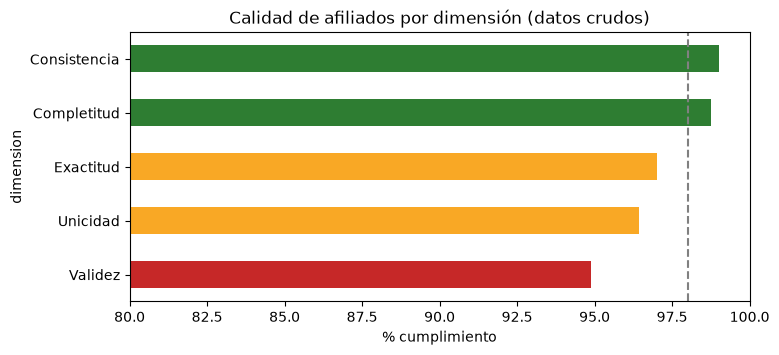

In [20]:
indice_dim = reporte.groupby("dimension")["cumplimiento_%"].mean().round(2).sort_values()
indice_global = round(indice_dim.mean(), 2)
print(indice_dim)
print(f"\nÍNDICE GLOBAL DE CALIDAD: {indice_global} % {semaforo(indice_global)}")

colores = ["#2e7d32" if v >= 98 else "#f9a825" if v >= 95 else "#c62828" for v in indice_dim]
ax = indice_dim.plot.barh(color=colores, figsize=(8, 3.5))
ax.axvline(98, ls="--", color="gray")
ax.set_xlim(80, 100)
ax.set_xlabel("% cumplimiento")
ax.set_title("Calidad de afiliados por dimensión (datos crudos)")
plt.show()

**✏️ Ejercicio 14 · Cuarentena.** Agrega a una copia de `afiliados` la columna `errores` y separa:
`validos` (sin falla crítica) y `cuarentena` (con al menos una). ¿Cuántos registros hay en cada una?
¿Cuáles son las combinaciones de errores más frecuentes en cuarentena?

In [21]:
marcado = afiliados.assign(errores=errores)
validos = marcado[~critica]
cuarentena = marcado[critica]
print("Válidos:", len(validos), "| Cuarentena:", len(cuarentena),
      f"({len(cuarentena) / len(marcado):.1%})")
cuarentena["errores"].value_counts().head(8)

Válidos: 2621 | Cuarentena: 499 (16.0%)


errores
salario_minimo                           110
documento_formato                         99
fila_no_duplicada; documento_unico        54
documento_unico                           22
pensionado_edad_minima                    19
genero_dominio; salario_minimo            11
documento_formato; ciudad_en_catalogo     11
ciudad_en_catalogo; salario_minimo        11
Name: count, dtype: int64

## Parte 4 · El mismo motor, otras tablas (10 min)
**✏️ Ejercicio 15 · PQRS.** Completa el catálogo de PQRS con la regla de **oportunidad**: respuesta en máximo
**15 días hábiles** (`np.busday_count`). Ejecuta el motor y muestra el reporte.

In [22]:
def dias_habiles(df):
    rad, resp = pd.to_datetime(df["fecha_radicacion"]), pd.to_datetime(df["fecha_respuesta"])
    m = resp.notna()
    dias = pd.Series(np.nan, index=df.index)
    dias[m] = np.busday_count(rad[m].values.astype("datetime64[D]"), resp[m].values.astype("datetime64[D]"))
    return dias

REGLAS_PQRS = [
    {"nombre": "radicado_unico", "dimension": "Unicidad", "severidad": "crítica",
     "valida": lambda df: ~df["radicado"].duplicated()},
    {"nombre": "cerrado_con_fecha", "dimension": "Completitud", "severidad": "crítica",
     "valida": lambda df: (df["estado"] != "Cerrado") | df["fecha_respuesta"].notna()},
    {"nombre": "respuesta_despues_radicacion", "dimension": "Consistencia", "severidad": "crítica",
     "valida": lambda df: df["fecha_respuesta"].isna()
                          | (pd.to_datetime(df["fecha_respuesta"]) >= pd.to_datetime(df["fecha_radicacion"]))},
]

In [23]:
REGLAS_PQRS.append(
    {"nombre": "respuesta_15_dias_habiles", "dimension": "Oportunidad", "severidad": "advertencia",
     "valida": lambda df: dias_habiles(df).isna() | (dias_habiles(df) <= 15)}
)
rep_pqrs, err_pqrs, crit_pqrs = evaluar(pqrs, REGLAS_PQRS)
rep_pqrs["semaforo"] = rep_pqrs["cumplimiento_%"].map(semaforo)
display(rep_pqrs)
d = dias_habiles(pqrs)
print("Días hábiles de respuesta — mediana:", d.median(), "| máximo:", d.max())

,regla,dimension,severidad,evaluados,fallas,cumplimiento_%,semaforo
0,radicado_unico,Unicidad,crítica,1500,0,100.00,🟢
1,cerrado_con_fecha,Completitud,crítica,1500,30,98.00,🟢
2,respuesta_despues_radicacion,Consistencia,crítica,1500,14,99.07,🟢
3,respuesta_15_dias_habiles,Oportunidad,advertencia,1500,165,89.00,🔴


Días hábiles de respuesta — mediana: 7.0 | máximo: 39.0


**✏️ Ejercicio 16 · Aportes.** Crea `REGLAS_APORTES` con al menos estas tres reglas y evalúa los aportes de marzo:
- `aporte_16_pct` (Exactitud): `|valor_aporte − round(ibc × 0.16)| ≤ 1`
- `ibc_minimo` (Exactitud): `ibc ≥ SMMLV`
- `afiliado_existe` (Integridad referencial): el `id_afiliado` está en `afiliados`

In [24]:
REGLAS_APORTES = [
    {"nombre": "aporte_16_pct", "dimension": "Exactitud", "severidad": "crítica",
     "valida": lambda df: (df["valor_aporte"] - (df["ibc"] * 0.16).round()).abs() <= 1},
    {"nombre": "ibc_minimo", "dimension": "Exactitud", "severidad": "crítica",
     "valida": lambda df: df["ibc"] >= SMMLV},
    {"nombre": "afiliado_existe", "dimension": "Integridad referencial", "severidad": "crítica",
     "valida": lambda df: df["id_afiliado"].isin(afiliados["id_afiliado"])},
    {"nombre": "aporte_no_duplicado", "dimension": "Unicidad", "severidad": "crítica",
     "valida": lambda df: ~df.duplicated(subset=["id_afiliado", "periodo"])},
]
rep_aportes, err_aportes, crit_aportes = evaluar(aportes, REGLAS_APORTES)
rep_aportes["semaforo"] = rep_aportes["cumplimiento_%"].map(semaforo)
display(rep_aportes)
print("Valor de aportes en cuarentena: $", f"{aportes.loc[crit_aportes, 'valor_aporte'].sum():,.0f}")

,regla,dimension,severidad,evaluados,fallas,cumplimiento_%,semaforo
0,aporte_16_pct,Exactitud,crítica,1770,18,98.98,🟢
1,ibc_minimo,Exactitud,crítica,1770,8,99.55,🟢
2,afiliado_existe,Integridad referencial,crítica,1770,8,99.55,🟢
3,aporte_no_duplicado,Unicidad,crítica,1770,5,99.72,🟢


Valor de aportes en cuarentena: $ 18,208,300


## Parte 5 · Medir → limpiar → volver a medir (5 min)
La función `limpiar_minimo` aplica lo de la Sesión 2 (versión corta). Ejecútala y compara el índice **antes y después**.

In [25]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

def clave_ciudad(s):
    return sin_tildes(str(s)).lower().strip().replace(".", "").replace(" dc", "")

EXTRA_CIUDADES = {"santiago de cali": "Cali", "b/quilla": "Barranquilla",
                  "cartagena de indias": "Cartagena", "b/manga": "Bucaramanga"}
MAPA_CIUDAD = {clave_ciudad(c): c for c in cat_ciudades["ciudad"]} | EXTRA_CIUDADES

def limpiar_minimo(df):
    df = df.drop_duplicates().copy()
    df["numero_documento"] = df["numero_documento"].str.replace(r"\D", "", regex=True)
    df["nombres"] = df["nombres"].str.strip().str.title()
    df["apellidos"] = df["apellidos"].str.strip().str.title()
    df["genero"] = df["genero"].str.strip().str.upper().str[0]
    df["estado"] = (df["estado"].str.strip().str.capitalize()
                    .replace({"Pensionada": "Pensionado"}))
    claves = df["ciudad"].map(clave_ciudad)
    df["ciudad"] = claves.map(MAPA_CIUDAD).fillna(df["ciudad"])
    df["email"] = df["email"].str.strip().str.lower()
    df["salario_base"] = pd.to_numeric(df["salario_base"].str.replace(".", "", regex=False), errors="coerce")
    return df

**✏️ Ejercicio 17.** Limpia, vuelve a evaluar y arma una tabla comparativa del índice por dimensión **antes vs. después**. ¿Qué dimensiones mejoraron? ¿Cuáles **no** y por qué?

In [26]:
afiliados_limpio = limpiar_minimo(afiliados)
rep2, err2, crit2 = evaluar(afiliados_limpio, REGLAS_AFILIADOS)
comparativo = pd.DataFrame({
    "antes": reporte.groupby("dimension")["cumplimiento_%"].mean(),
    "despues": rep2.groupby("dimension")["cumplimiento_%"].mean(),
}).round(2)
comparativo.loc["ÍNDICE GLOBAL"] = comparativo.mean().round(2)
comparativo["mejora"] = (comparativo["despues"] - comparativo["antes"]).round(2)
print("Filas:", len(afiliados), "→", len(afiliados_limpio),
      "| Cuarentena:", int(critica.sum()), "→", int(crit2.sum()))
comparativo

Filas: 3120 → 3030 | Cuarentena: 499 → 214


,antes,despues,mejora
dimension,,,
Completitud,98.74,98.74,0.00
Consistencia,99.02,98.99,-0.03
Exactitud,97.00,98.05,1.05
Unicidad,96.42,99.28,2.86
Validez,94.88,98.69,3.81
ÍNDICE GLOBAL,97.21,98.75,1.54


✍️ *Tu respuesta:* Mejoran **Validez (+3,81 pp)**, **Unicidad (+2,86 pp)** y **Exactitud (+1,05 pp)**:
estandarizar mayúsculas/tildes, quitar puntos del documento, normalizar ciudad y estado y convertir el salario a
número hace que las reglas de formato, dominio y rango se cumplan.

**Completitud no cambia (98,74 %)**: `limpiar_minimo` no imputa el género ni el documento; los vacíos siguen ahí.
**Consistencia baja levemente (−0,03 pp)**: al normalizar las ciudades ahora hay más registros comparables contra el
catálogo y siguen existiendo incoherencias ciudad–departamento y pensionados sin la edad mínima, que la limpieza no
corrige (son errores de negocio, no de formato).

La limpieza **no puede inventar** una fecha de nacimiento correcta ni el salario real de alguien: por eso las reglas
de Exactitud crítica y las inconsistencias de negocio terminan en **cuarentena para revisión manual**, no se
"arreglan" solas.

## 🎯 Reto de cierre
1. Agrega a `REGLAS_APORTES` la regla **`pago_oportuno`** (Oportunidad): la `fecha_pago` debe ser a más tardar el
   **último día del mes siguiente** al `periodo`. Pista: `pd.to_datetime(df["periodo"]) + pd.offsets.MonthEnd(2)`.
2. Escribe una regla propia para `afiliados` que no hayamos visto y explica a qué dimensión pertenece.
3. **Para la gerencia:** en 3 líneas, ¿se puede confiar en la base de afiliados? Usa el índice global y las 2 reglas
   más críticas como evidencia.

In [27]:
# Reto 1 · pago oportuno (Oportunidad): a más tardar el último día del mes siguiente
REGLAS_APORTES.append(
    {"nombre": "pago_oportuno", "dimension": "Oportunidad", "severidad": "advertencia",
     "valida": lambda df: pd.to_datetime(df["fecha_pago"])
                          <= pd.to_datetime(df["periodo"]) + pd.offsets.MonthEnd(2)}
)
rep_aportes, _, _ = evaluar(aportes, REGLAS_APORTES)
display(rep_aportes)

# Reto 2 · regla propia: un correo no debería estar compartido entre afiliados (Unicidad)
REGLAS_AFILIADOS.append(
    {"nombre": "email_unico", "dimension": "Unicidad", "severidad": "advertencia",
     "valida": lambda df: df["email"].isna() | ~df["email"].duplicated()}
)
rep_reto, _, _ = evaluar(afiliados, REGLAS_AFILIADOS)
print("Reglas en el catálogo:", len(REGLAS_AFILIADOS))
print(rep_reto[rep_reto["regla"] == "email_unico"].to_string(index=False))

# Reto 3 · los tres mensajes para la gerencia, con las cifras del reporte
criticas = reporte[reporte["severidad"] == "crítica"].sort_values("cumplimiento_%")
peor, segunda = criticas.iloc[0], criticas.iloc[1]
print(f"""
PARA LA GERENCIA
1. La base NO está lista para usarse sin control: índice global {indice_global} % y
   {len(cuarentena)} de {len(marcado)} afiliados ({len(cuarentena) / len(marcado):.1%}) con al menos una falla crítica.
2. Las reglas críticas más débiles son {peor['regla']} ({peor['cumplimiento_%']} %) y
   {segunda['regla']} ({segunda['cumplimiento_%']} %): afectan identificación y cálculo de aportes.
3. Usar ya los {len(validos)} registros válidos; corregir los {len(cuarentena)} en cuarentena antes de decidir sobre personas.
""")

,regla,dimension,severidad,evaluados,fallas,cumplimiento_%
0,aporte_16_pct,Exactitud,crítica,1770,18,98.98
1,ibc_minimo,Exactitud,crítica,1770,8,99.55
2,afiliado_existe,Integridad referencial,crítica,1770,8,99.55
3,aporte_no_duplicado,Unicidad,crítica,1770,5,99.72
4,pago_oportuno,Oportunidad,advertencia,1770,88,95.03


Reglas en el catálogo: 16
      regla dimension   severidad  evaluados  fallas  cumplimiento_%
email_unico  Unicidad advertencia       3120     131            95.8

PARA LA GERENCIA
1. La base NO está lista para usarse sin control: índice global 97.21 % y
   499 de 3120 afiliados (16.0%) con al menos una falla crítica.
2. Las reglas críticas más débiles son salario_minimo (94.42 %) y
   documento_formato (94.68 %): afectan identificación y cálculo de aportes.
3. Usar ya los 2621 registros válidos; corregir los 499 en cuarentena antes de decidir sobre personas.



✍️ **Respuesta al reto.**

**Reto 2 — regla propia: `email_unico` (dimensión Unicidad, severidad advertencia).**
Un mismo correo en dos afiliados distintos sugiere un error de captura o un duplicado encubierto (la persona quedó
registrada dos veces con documentos diferentes). La regla solo aplica cuando hay correo: `df["email"].isna() | ~df["email"].duplicated()`.
No se marca como crítica porque un correo compartido también puede ser legítimo (un acudiente, una empresa), así que
se revisa, no se bloquea.

**Reto 3 — para la gerencia.**
1. **No se puede confiar todavía en toda la base:** el índice global es **97,21 %** (amarillo) y **499 de 3.120**
   afiliados (**16,0 %**) tienen al menos una falla crítica.
2. Las reglas críticas más débiles son **`salario_minimo` (94,42 %)** y **`documento_formato` (94,68 %)**: afectan
   justo lo que se usa para identificar a la persona y calcular sus aportes; a ellas se suma **`documento_unico`**
   (134 documentos repetidos).
3. **Recomendación:** usar de inmediato los **2.621 registros válidos** para analítica y reportes, y llevar los 499
   restantes a cuarentena para corrección antes de cualquier decisión sobre personas. No se debe presentar el
   97,21 % como "todo bien": el semáforo amarillo exige un plan de depuración.